Calcolo presenze per ogni base:
Basi analizzate: 5

Presenze su s=20 estrazioni 
per campioni di ampiezza alfa=15:

Analisi evidenze: (U(k), V(k), W(k), Y(k))
Statistiche sommari:

Valori per estratto singolo
- mean    : [6.6 4.2 1.8 2.4]
- std     : [1.62 1.17 1.17 0.49]
- skewness: [ 0.38  0.36 -0.36  0.41]
- q1      : [5. 3. 1. 2.]
- q3      : [8. 5. 3. 3.]
  Distribuzione simmetrica: 
  (media e deviazione standard):
    Totale presenze                      [range U(k)]: 5.0 .. 8.0, copertura: 80.0%
    Combinazioni con almeno una presenza [range V(k)]: 3.0 .. 5.0, copertura: 80.0%
    Combinazioni senza presenze          [range W(k)]: 1.0 .. 3.0, copertura: 80.0%
    Massima frequenza di presenza        [range Y(k)]: 2.0 .. 3.0, copertura: 100.0%
  (quartili):
    Totale presenze                      [range U(k)]: 5.0 .. 8.0, copertura: 80.0%
    Combinazioni con almeno una presenza [range V(k)]: 3.0 .. 5.0, copertura: 80.0%
    Combinazioni senza presenze          [range W(k)]: 1

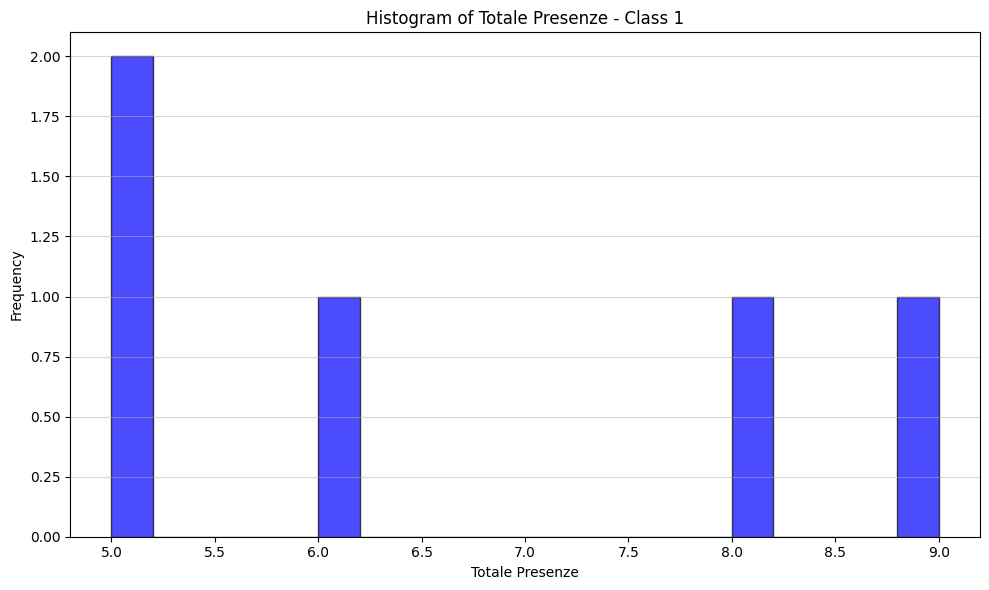

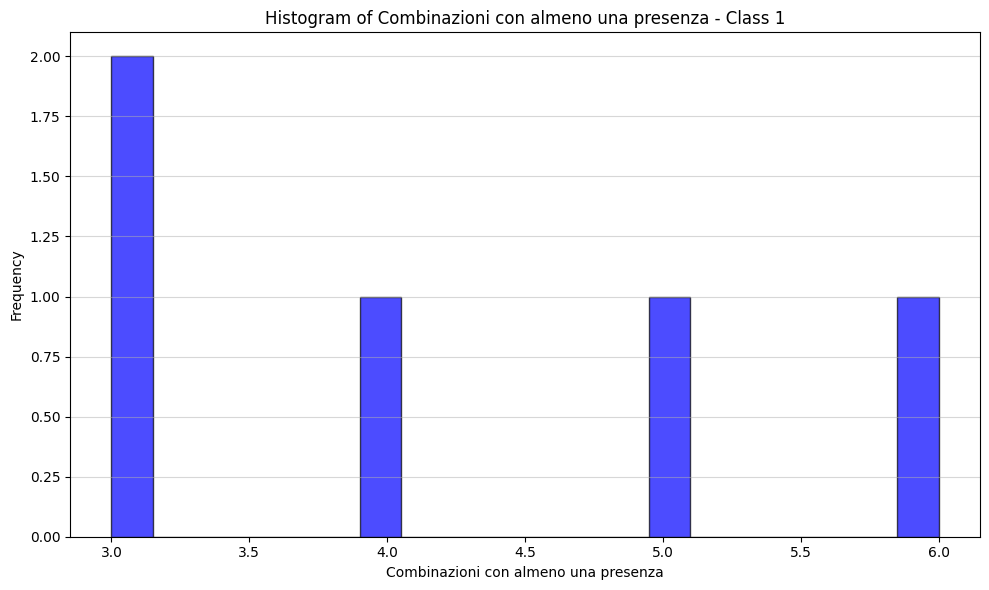

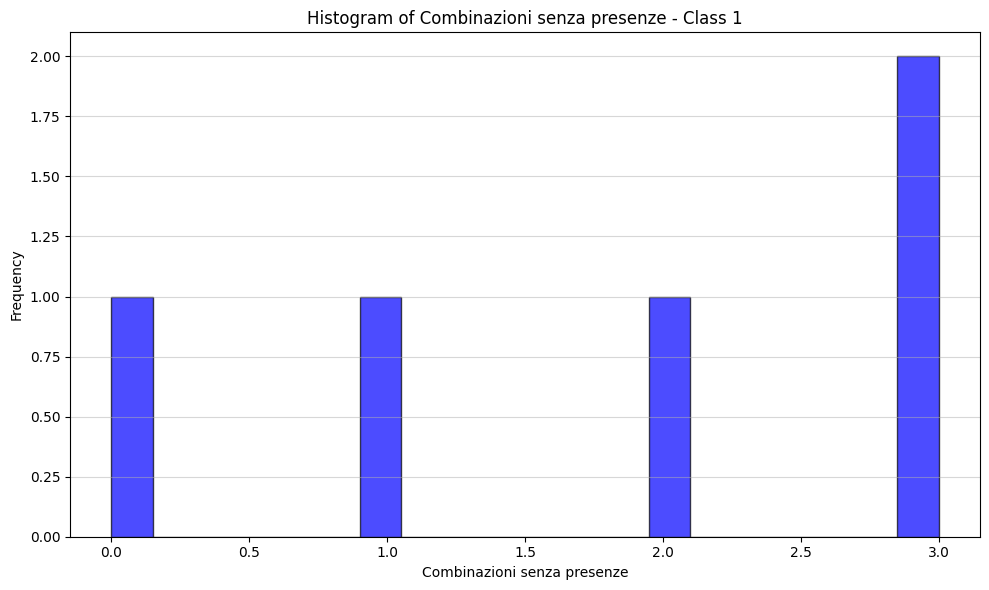

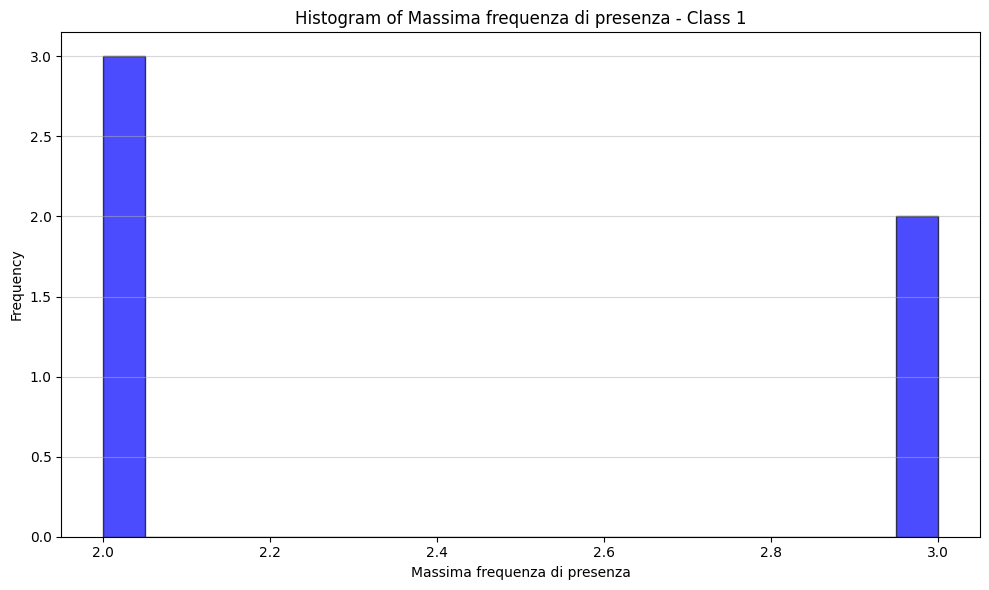

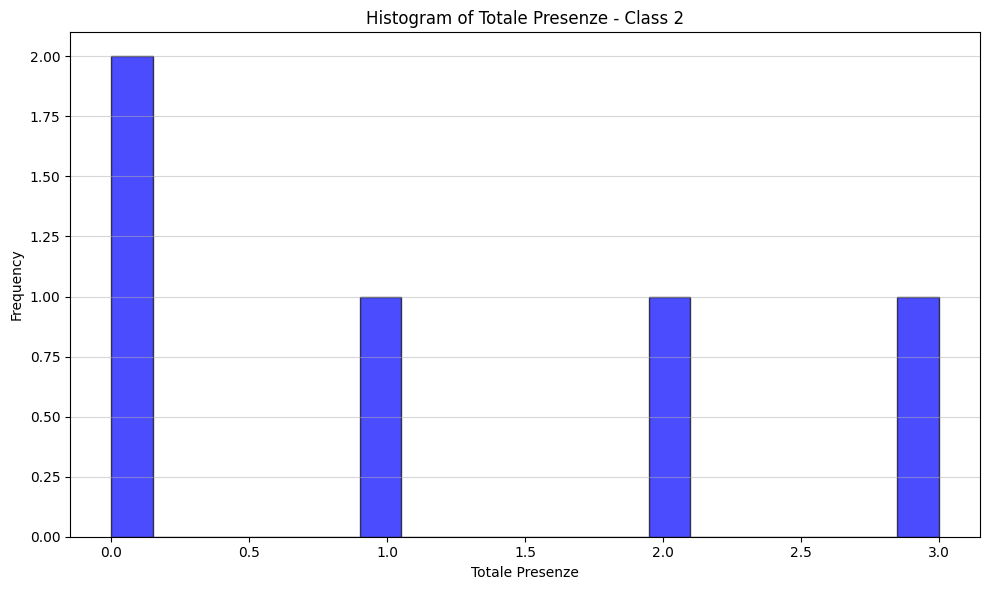

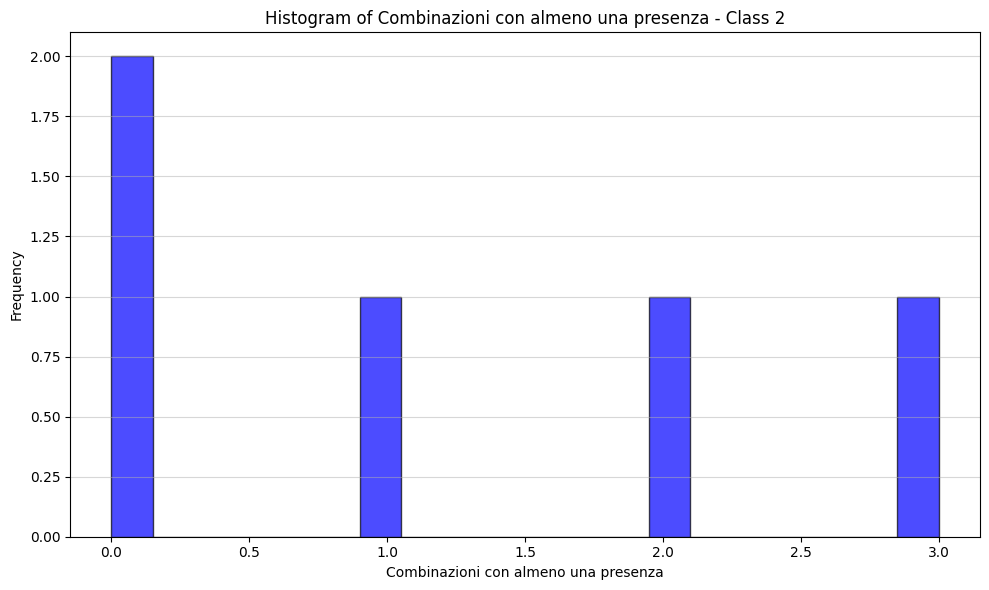

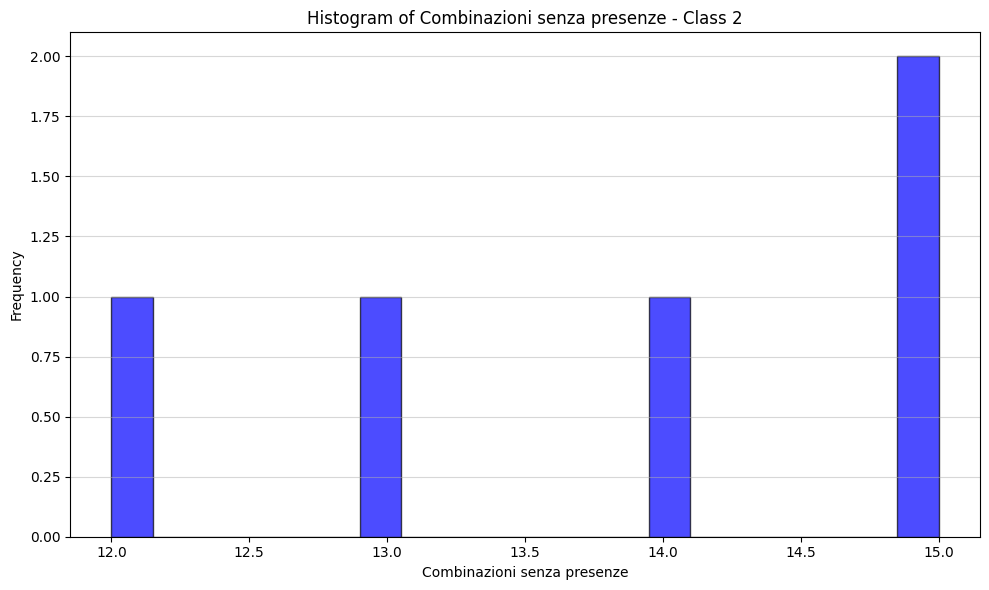

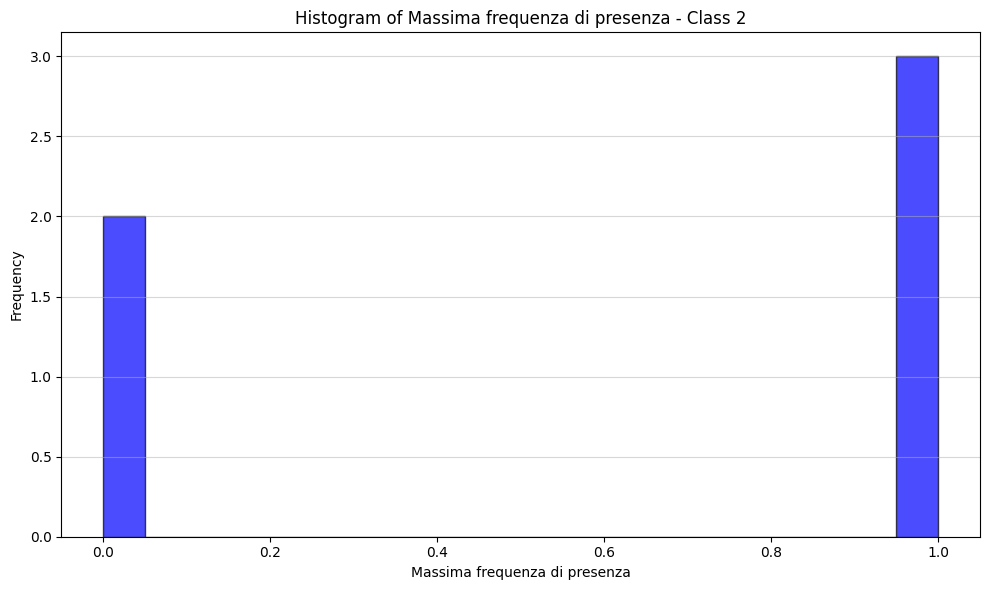

In [10]:
import sys
import os

# Navigate from test/ to src/ using relative path
notebook_dir = os.path.dirname(os.path.abspath('.'))
src_path = os.path.join(notebook_dir,  'src')
sys.path.insert(0, src_path)

from common_lib import CommonLib
from stats_lib import OccurencesStats

import numpy as np
from itertools import combinations
from scipy.special import comb
from scipy import stats
import matplotlib.pyplot as plt


def print_graph_info(s,i):    
    for j in range(0,4):
        vx = [x[j] for x in s]
        print(f"\nElenco colonna {j+1} per classe k {i+1}:")
        (uniq, freq) = (np.unique(vx, return_counts=True))
        print(np.column_stack((uniq,freq)))
        
def  draw_histogram(data, k, description):
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.hist(data, bins=20, color='blue', edgecolor='black', alpha=0.7)
    ax.set_title(f'Histogram of {description} - Class {k+1}')
    ax.set_xlabel(f'{description}')
    ax.set_ylabel('Frequency')
    ax.grid(axis='y', alpha=0.5)
    plt.tight_layout()
    plt.show()

##############################################################################

data_file_name = "../data/estrazioni_2026_2006_copy.csv"
clib = CommonLib(data_file_name)
ostats = OccurencesStats()

# Popolazione
history_data = clib.load_data(20) # Carica le estrazioni da un file CSV
# Intervalli di campionamento
sample_size = 15 # Numero di estrazioni da considerare per il campione (es. 60 estrazioni più recenti)

# Frequenza presenze per intervallo di campionamento   
print("Calcolo presenze per ogni base:")     
occurrences = ostats.find_occurrences(history_data, sample_size)
print("Basi analizzate:", len(history_data) - sample_size)

#  Sommario dei risultati per ogni classe di combinazioni
print(f"\nPresenze su s={len(history_data)} estrazioni \nper campioni di ampiezza alfa={sample_size}:")
summaries = ostats.occurrences_summary(occurrences)

# Stampa dei risultati riassuntivi per ogni classe di combinazioni
print ("\nAnalisi evidenze: (U(k), V(k), W(k), Y(k))") 
ostats.calc_statistics(summaries)
        
        #print(f"    Somma dei sommari filtrati per classe k={i+1}: {risultato}")
        #print(f"    Copertura percentuale: {copertura}")
        
print("\nsommario completo.")

# Histogram
descr = ['Totale Presenze', 'Combinazioni con almeno una presenza', 'Combinazioni senza presenze', 'Massima frequenza di presenza'] 
for k in range(0,2):
    for j in range(0,4):
        data_column = [s[j] for s in summaries[k]]
        draw_histogram(data_column, k, descr[j])



In [7]:
import sys
import os

# Navigate from test/ to src/ using relative path
notebook_dir = os.path.dirname(os.path.abspath('.'))
print(f"Notebook directory: {notebook_dir}")
src_path = os.path.join(notebook_dir,  'src')
print(f"Source path: {src_path}")
sys.path.insert(0, src_path)
print(f"Current sys.path: {sys.path}")

from common_lib import CommonLib
from stats_lib import OccurencesStats

Notebook directory: /home/super8/superenalotto
Source path: /home/super8/superenalotto/src
Current sys.path: ['/home/super8/superenalotto/src', '/home/super8/superenalotto/superenalotto/src', '/home/super8', '/home/super8/superenalotto/superenalotto/src', '/home/super8', '/home/super8/superenalotto/superenalotto/src', '/home/super8', '/home/super8/superenalotto/superenalotto/src', '/home/super8/superenalotto/superenalotto/src', '/home/super8/superenalotto/superenalotto/src', '/usr/lib/python312.zip', '/usr/lib/python3.12', '/usr/lib/python3.12/lib-dynload', '', '/home/super8/lib/python3.12/site-packages']
